In [ ]:
# Import Datasets
import pandas as pd
data= pd.read_excel('/content/HHS_Unaccompanied_Alien_Children_Program.csv.xlsx')
data.head()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Corrected Date,Days Between Records,Earliest Date,Latest Date
0,"January 12, 2023",33,53,34,6566,436,2023-01-12,NaN,2023-01-12,2025-12-21
1,"January 22, 2023",32,49,39,7122,227,2023-01-22,10.0,NaT,NaT
2,"January 23, 2023",32,50,39,7280,181,2023-01-23,1.0,NaT,NaT
3,"January 24, 2023",47,42,47,7433,175,2023-01-24,1.0,NaT,NaT
4,"January 25, 2023",20,22,41,7538,180,2023-01-25,1.0,NaT,NaT


In [ ]:
# Data Cleaning
data.shape      # Total Rows & Columns


(720, 10)

In [ ]:
data.index      # Row names of the Dataframe

RangeIndex(start=0, stop=720, step=1)

In [ ]:
data.columns    # Column names of the Dataframe

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care',
       'Corrected Date', 'Days Between Records', 'Earliest Date',
       'Latest Date'],
      dtype='object')

In [ ]:
data.info      # Basic info about the Dataframe

<bound method DataFrame.info of                   Date  Children apprehended and placed in CBP custody*  \
0     January 12, 2023                                               33   
1     January 22, 2023                                               32   
2     January 23, 2023                                               32   
3     January 24, 2023                                               47   
4     January 25, 2023                                               20   
..                 ...                                              ...   
715  December 15, 2025                                               11   
716  December 16, 2025                                                8   
717  December 17, 2025                                                7   
718  December 18, 2025                                               11   
719  December 21, 2025                                                6   

     Children in CBP custody  Children transferred out of CBP custody  \
0                         53                                       34   
1                         49                                       39   
2                         50                                       39   
3                         42                                       47   
4                         22                                       41   
..                       ...                                      ...   
715                       42                                        9   
716                       54                                       15   
717                       31                                       11   
718                       50                                        6   
719                       18                                       11   

     Children in HHS Care  Children discharged from HHS Care Corrected Date  \
0                    6566                                436     2023-01-12   
1                    7122                                227     2023-01-22   
2                    7280                                181     2023-01-23   
3                    7433                                175     2023-01-24   
4                    7538                                180     2023-01-25   
..                    ...                                ...            ...   
715                  2470                                  7     2025-12-15   
716                  2468                                  9     2025-12-16   
717                  2481                                 10     2025-12-17   
718                  2472                                 16     2025-12-18   
719                  2484                                 14     2025-12-21   

     Days Between Records Earliest Date Latest Date  
0                     NaN    2023-01-12  2025-12-21  
1                    10.0           NaT         NaT  
2                     1.0           NaT         NaT  
3                     1.0           NaT         NaT  
4                     1.0           NaT         NaT  
..                    ...           ...         ...  
715                   1.0           NaT         NaT  
716                   1.0           NaT         NaT  
717                   1.0           NaT         NaT  
718                   1.0           NaT         NaT  
719                   3.0           NaT         NaT  

[720 rows x 10 columns]>

In [ ]:
data.isnull().sum()       # Checking Null/ Missing Values

,0
Date,0
Children apprehended and placed in CBP custody*,0
Children in CBP custody,0
Children transferred out of CBP custody,0
Children in HHS Care,0
Children discharged from HHS Care,0
Corrected Date,0
Days Between Records,1
Earliest Date,719
Latest Date,719


In [ ]:
# Keeping only the original six dataset columns

columns_to_keep = [
    'Date',
    'Children apprehended and placed in CBP custody*',
    'Children in CBP custody',
    'Children transferred out of CBP custody',
    'Children in HHS Care',
    'Children discharged from HHS Care'
]

data = data[columns_to_keep].copy()

# Ensure dates and numeric values are correctly formatted
data['Date'] = pd.to_datetime(data['Date'], errors='coerce')

numeric_columns = columns_to_keep[1:]

for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Sort chronologically
data = data.sort_values('Date').reset_index(drop=True)

print("Dataset shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

data.head()

Dataset shape: (720, 6)

Missing values:
Date                                               0
Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
dtype: int64


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2023-01-12,33,53,34,6566,436
1,2023-01-22,32,49,39,7122,227
2,2023-01-23,32,50,39,7280,181
3,2023-01-24,47,42,47,7433,175
4,2023-01-25,20,22,41,7538,180


In [ ]:
# Select the variable we want to forecast
target = 'Children in HHS Care'

# Remove rows where the date or target value is missing
forecast_data = data[['Date', target]].dropna().copy()

# Sort records chronologically
forecast_data = forecast_data.sort_values('Date').reset_index(drop=True)

# Use the first 80% for training and the last 20% for testing
split_index = int(len(forecast_data) * 0.8)

train = forecast_data.iloc[:split_index].copy()
test = forecast_data.iloc[split_index:].copy()

print("Total records:", len(forecast_data))
print("Training records:", len(train))
print("Testing records:", len(test))

print("\nTraining period:")
print(train['Date'].min(), "to", train['Date'].max())

print("\nTesting period:")
print(test['Date'].min(), "to", test['Date'].max())

Total records: 720
Training records: 576
Testing records: 144

Training period:
2023-01-12 00:00:00 to 2025-05-13 00:00:00

Testing period:
2025-05-14 00:00:00 to 2025-12-21 00:00:00


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual values from the test period
actual = test['Children in HHS Care'].to_numpy()

# Naive forecast: each prediction uses the previous day's actual value
history = list(train['Children in HHS Care'].to_numpy())
predictions = []

for value in actual:
    predictions.append(history[-1])
    history.append(value)

predictions = np.array(predictions)

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))

# Avoid division by zero in MAPE
nonzero = actual != 0
mape = (
    np.mean(np.abs((actual[nonzero] - predictions[nonzero])
                   / actual[nonzero])) * 100
    if nonzero.any() else np.nan
)

print("Naive Forecast Results")
print("----------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE (%):", round(mape, 2))

results = test[['Date']].copy()
results['Actual'] = actual
results['Predicted'] = predictions

display(results.head(10))

Naive Forecast Results
----------------------
MAE: 10.39
RMSE: 14.17
MAPE (%): 0.46


,Date,Actual,Predicted
576,2025-05-14,2394,2394
577,2025-05-15,2410,2394
578,2025-05-18,2437,2410
579,2025-05-19,2457,2437
580,2025-05-21,2467,2457
581,2025-05-22,2473,2467
582,2025-05-27,2504,2473
583,2025-05-28,2499,2504
584,2025-05-29,2506,2499
585,2025-06-01,2528,2506


In [ ]:
# 7-day moving-average forecast

actual = test['Children in HHS Care'].to_numpy()

history = list(train['Children in HHS Care'].to_numpy())
moving_predictions = []

for value in actual:
    prediction = np.mean(history[-7:])
    moving_predictions.append(prediction)
    history.append(value)

moving_predictions = np.array(moving_predictions)

# Evaluate the model
mae_ma = mean_absolute_error(actual, moving_predictions)
rmse_ma = np.sqrt(mean_squared_error(actual, moving_predictions))

nonzero = actual != 0
mape_ma = (
    np.mean(np.abs(
        (actual[nonzero] - moving_predictions[nonzero])
        / actual[nonzero]
    )) * 100
    if nonzero.any() else np.nan
)

print("7-Day Moving Average Forecast")
print("-----------------------------")
print("MAE:", round(mae_ma, 2))
print("RMSE:", round(rmse_ma, 2))
print("MAPE (%):", round(mape_ma, 2))

7-Day Moving Average Forecast
-----------------------------
MAE: 33.25
RMSE: 40.61
MAPE (%): 1.48


In [ ]:
# Compare both models
comparison = pd.DataFrame({
    'Model': ['Naive Forecast', '7-Day Moving Average'],
    'MAE': [mae, mae_ma],
    'RMSE': [rmse, rmse_ma],
    'MAPE (%)': [mape, mape_ma]
})

display(comparison.round(2))

best_model = comparison.loc[comparison['MAE'].idxmin(), 'Model']
print("Better model based on MAE:", best_model)

,Model,MAE,RMSE,MAPE (%)
0,Naive Forecast,10.39,14.17,0.46
1,7-Day Moving Average,33.25,40.61,1.48


Better model based on MAE: Naive Forecast


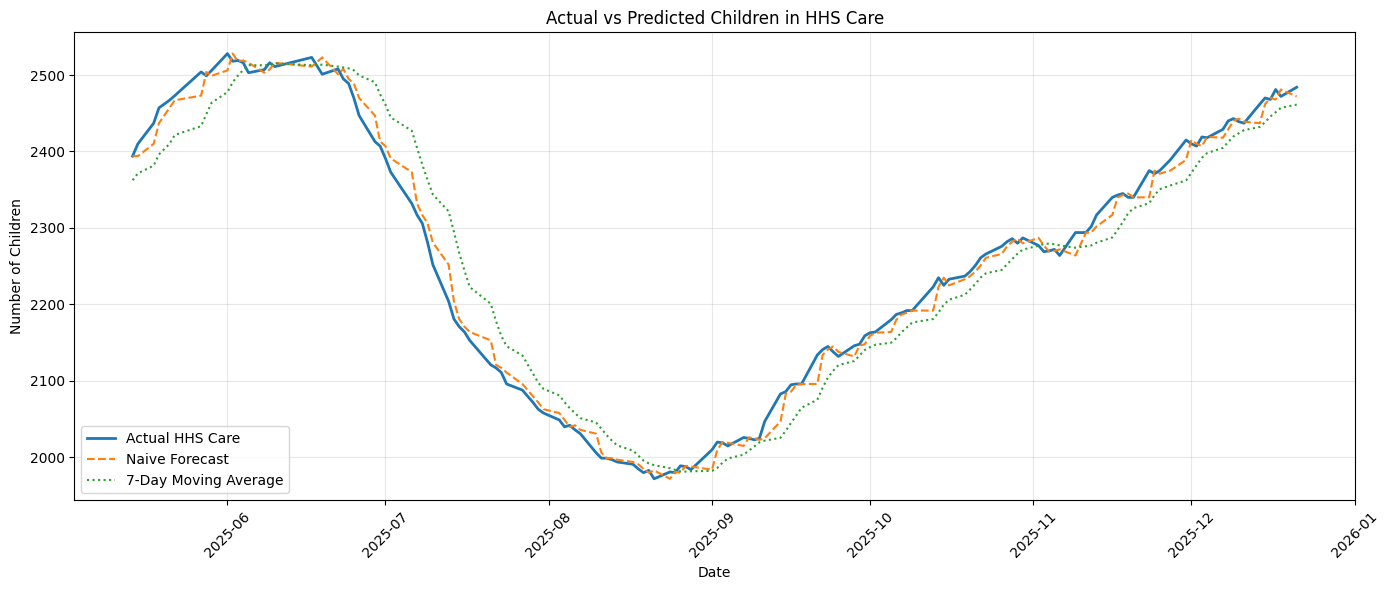

In [ ]:
# Chart comparing the actual number of children in HHS Care with the predictions from both models

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    test['Date'],
    actual,
    label='Actual HHS Care',
    linewidth=2
)

plt.plot(
    test['Date'],
    predictions,
    label='Naive Forecast',
    linestyle='--'
)

plt.plot(
    test['Date'],
    moving_predictions,
    label='7-Day Moving Average',
    linestyle=':'
)

plt.title('Actual vs Predicted Children in HHS Care')
plt.xlabel('Date')
plt.ylabel('Number of Children')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Statistical forecasting model of ARIMA

!pip install statsmodels -q

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Prepare the training and testing series
train_series = train.set_index('Date')['Children in HHS Care']
test_series = test.set_index('Date')['Children in HHS Care']

print("Training observations:", len(train_series))
print("Testing observations:", len(test_series))
print("ARIMA preparation completed.")

Training observations: 576
Testing observations: 144
ARIMA preparation completed.


In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a continuous daily date index
daily_data = data[['Date', 'Children in HHS Care']].copy()
daily_data['Date'] = pd.to_datetime(daily_data['Date'])
daily_data = daily_data.sort_values('Date')
daily_data = daily_data.drop_duplicates(subset='Date')
daily_data = daily_data.set_index('Date').asfreq('D')

# Fill missing dates using time interpolation
daily_data['Children in HHS Care'] = (
    daily_data['Children in HHS Care'].interpolate(method='time')
)

# Split chronologically: first 80%, last 20%
split_index = int(len(daily_data) * 0.8)
train_series = daily_data['Children in HHS Care'].iloc[:split_index]
test_series = daily_data['Children in HHS Care'].iloc[split_index:]

# Fit ARIMA and forecast the test period
arima_fit = ARIMA(
    train_series,
    order=(1, 1, 1)
).fit()

arima_predictions = arima_fit.forecast(steps=len(test_series))

# Evaluate
arima_mae = mean_absolute_error(test_series, arima_predictions)
arima_rmse = np.sqrt(mean_squared_error(test_series, arima_predictions))

nonzero = test_series.to_numpy() != 0
arima_mape = (
    np.mean(np.abs(
        (test_series.to_numpy()[nonzero]
         - arima_predictions.to_numpy()[nonzero])
        / test_series.to_numpy()[nonzero]
    )) * 100
    if nonzero.any() else np.nan
)

print("ARIMA(1,1,1) Results")
print("MAE:", round(arima_mae, 2))
print("RMSE:", round(arima_rmse, 2))
print("MAPE (%):", round(arima_mape, 2))

ARIMA(1,1,1) Results
MAE: 221.83
RMSE: 274.26
MAPE (%): 10.46


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Ensure the training and testing data are numeric
train_series = pd.to_numeric(train['Children in HHS Care']).reset_index(drop=True)
test_series = pd.to_numeric(test['Children in HHS Care']).reset_index(drop=True)

# Fit the ARIMA model
arima_model = ARIMA(train_series, order=(1, 1, 1))
arima_fit = arima_model.fit()

# Forecast the testing period
arima_predictions = arima_fit.forecast(
    steps=len(test_series)
)

# Calculate evaluation metrics
arima_mae = mean_absolute_error(test_series, arima_predictions)
arima_rmse = np.sqrt(mean_squared_error(test_series, arima_predictions))
arima_mape = np.mean(
    np.abs(
        (test_series.to_numpy() - np.asarray(arima_predictions))
        / np.where(test_series.to_numpy() == 0, np.nan, test_series.to_numpy())
    )
) * 100

print("ARIMA(1,1,1) Results")
print("--------------------")
print("MAE:", round(arima_mae, 2))
print("RMSE:", round(arima_rmse, 2))
print("MAPE (%):", round(arima_mape, 2))

ARIMA(1,1,1) Results
--------------------
MAE: 186.64
RMSE: 227.42
MAPE (%): 8.77


In [ ]:
comparison = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        '7-Day Moving Average',
        'ARIMA(1,1,1)'
    ],
    'MAE': [mae, mae_ma, arima_mae],
    'RMSE': [rmse, rmse_ma, arima_rmse],
    'MAPE (%)': [mape, mape_ma, arima_mape]
})

display(comparison.round(2))

best_model = comparison.loc[comparison['MAE'].idxmin(), 'Model']
print("Best model based on MAE:", best_model)

,Model,MAE,RMSE,MAPE (%)
0,Naive Forecast,10.39,14.17,0.46
1,7-Day Moving Average,33.25,40.61,1.48
2,"ARIMA(1,1,1)",186.64,227.42,8.77


Best model based on MAE: Naive Forecast


In [ ]:
# Visualize The Model Comparison

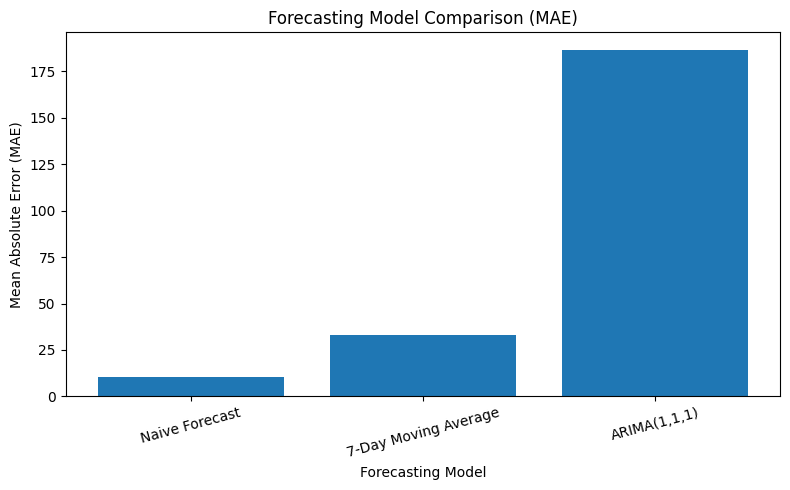

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(comparison['Model'], comparison['MAE'])

plt.title('Forecasting Model Comparison (MAE)')
plt.xlabel('Forecasting Model')
plt.ylabel('Mean Absolute Error (MAE)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

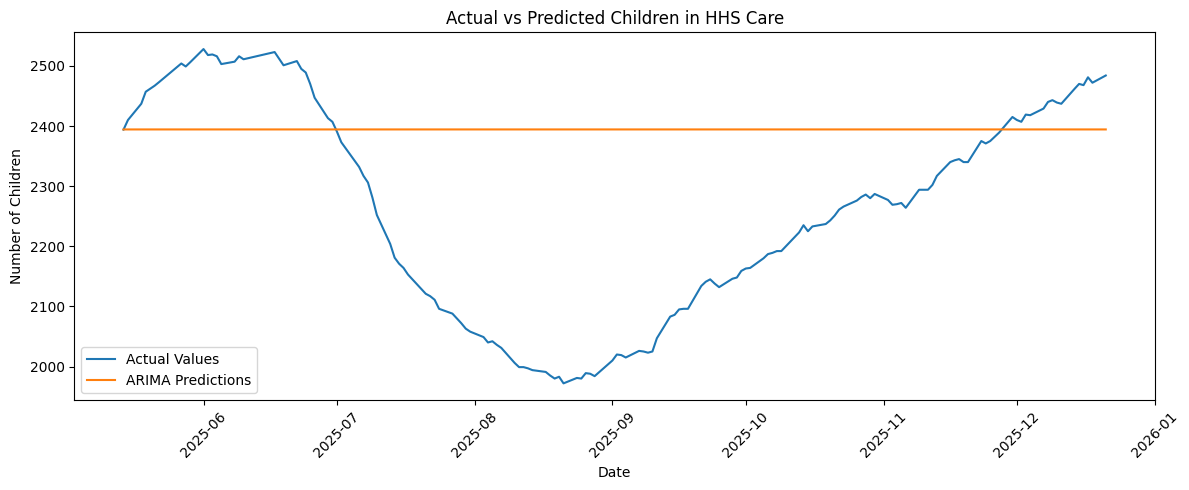

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    test['Date'].reset_index(drop=True),
    test_series,
    label='Actual Values'
)

plt.plot(
    test['Date'].reset_index(drop=True),
    arima_predictions,
    label='ARIMA Predictions'
)

plt.title('Actual vs Predicted Children in HHS Care')
plt.xlabel('Date')
plt.ylabel('Number of Children')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Final comparison table

comparison = comparison.sort_values('MAE').reset_index(drop=True)

comparison['Rank'] = range(1, len(comparison) + 1)

print("FINAL FORECASTING MODEL COMPARISON")
display(comparison.round(2))

print("\nBest model based on MAE:")
print(comparison.iloc[0]['Model'])

FINAL FORECASTING MODEL COMPARISON


,Model,MAE,RMSE,MAPE (%),Rank
0,Naive Forecast,10.39,14.17,0.46,1
1,7-Day Moving Average,33.25,40.61,1.48,2
2,"ARIMA(1,1,1)",186.64,227.42,8.77,3



Best model based on MAE:
Naive Forecast


In [ ]:
# Check daily date continuity

data['Date'] = pd.to_datetime(data['Date'], errors='coerce')
data = data.sort_values('Date').reset_index(drop=True)

print("First date:", data['Date'].min())
print("Last date:", data['Date'].max())
print("Total records:", len(data))
print("Duplicate dates:", data['Date'].duplicated().sum())

all_dates = pd.date_range(
    start=data['Date'].min(),
    end=data['Date'].max(),
    freq='D'
)

existing_dates = pd.DatetimeIndex(data['Date'].dropna().unique())
missing_dates = all_dates.difference(existing_dates)

print("Expected daily dates:", len(all_dates))
print("Missing dates:", len(missing_dates))
print("First 15 missing dates:", list(missing_dates[:15]))

First date: 2023-01-12 00:00:00
Last date: 2025-12-21 00:00:00
Total records: 720
Duplicate dates: 0
Expected daily dates: 1075
Missing dates: 355
First 15 missing dates: [Timestamp('2023-01-13 00:00:00'), Timestamp('2023-01-14 00:00:00'), Timestamp('2023-01-15 00:00:00'), Timestamp('2023-01-16 00:00:00'), Timestamp('2023-01-17 00:00:00'), Timestamp('2023-01-18 00:00:00'), Timestamp('2023-01-19 00:00:00'), Timestamp('2023-01-20 00:00:00'), Timestamp('2023-01-21 00:00:00'), Timestamp('2023-01-26 00:00:00'), Timestamp('2023-01-27 00:00:00'), Timestamp('2023-01-28 00:00:00'), Timestamp('2023-02-03 00:00:00'), Timestamp('2023-02-04 00:00:00'), Timestamp('2023-02-10 00:00:00')]


In [ ]:
# Examine the gaps between observations

date_gaps = data['Date'].sort_values().diff().dt.days.dropna()

print("Gap between consecutive records (days):")
print(date_gaps.describe())

print("\nMost common gap lengths:")
print(date_gaps.value_counts().head(10))

print("\nFirst 20 dates in the dataset:")
print(data['Date'].head(20).to_list())

Gap between consecutive records (days):
count    719.000000
mean       1.493741
std        1.001198
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max       10.000000
Name: Date, dtype: float64

Most common gap lengths:
Date
1.0     558
3.0     122
4.0      23
2.0      10
5.0       3
10.0      1
6.0       1
7.0       1
Name: count, dtype: int64

First 20 dates in the dataset:
[Timestamp('2023-01-12 00:00:00'), Timestamp('2023-01-22 00:00:00'), Timestamp('2023-01-23 00:00:00'), Timestamp('2023-01-24 00:00:00'), Timestamp('2023-01-25 00:00:00'), Timestamp('2023-01-29 00:00:00'), Timestamp('2023-01-30 00:00:00'), Timestamp('2023-01-31 00:00:00'), Timestamp('2023-02-01 00:00:00'), Timestamp('2023-02-02 00:00:00'), Timestamp('2023-02-05 00:00:00'), Timestamp('2023-02-06 00:00:00'), Timestamp('2023-02-07 00:00:00'), Timestamp('2023-02-08 00:00:00'), Timestamp('2023-02-09 00:00:00'), Timestamp('2023-02-12 00:00:00'), Timestamp('2023-02-13 00:00:00'), Timestamp

In [ ]:
# Check which weekdays are missing from the dataset

all_dates = pd.date_range(
    start=data['Date'].min(),
    end=data['Date'].max(),
    freq='D'
)

existing_dates = pd.DatetimeIndex(data['Date'].dropna().unique())
missing_dates = all_dates.difference(existing_dates)

missing_df = pd.DataFrame({'Missing_Date': missing_dates})
missing_df['Weekday'] = missing_df['Missing_Date'].dt.day_name()

print("Missing dates by weekday:")
print(missing_df['Weekday'].value_counts())

print("\nFirst 20 missing dates:")
display(missing_df.head(20))

Missing dates by weekday:
Weekday
Saturday     154
Friday       152
Sunday        24
Monday         8
Thursday       7
Wednesday      6
Tuesday        4
Name: count, dtype: int64

First 20 missing dates:


,Missing_Date,Weekday
0,2023-01-13,Friday
1,2023-01-14,Saturday
2,2023-01-15,Sunday
3,2023-01-16,Monday
4,2023-01-17,Tuesday
5,2023-01-18,Wednesday
6,2023-01-19,Thursday
7,2023-01-20,Friday
8,2023-01-21,Saturday
9,2023-01-26,Thursday


In [ ]:
# Count available observations by weekday

data['Weekday'] = data['Date'].dt.day_name()

print("Available records by weekday:")
print(data['Weekday'].value_counts().reindex([
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
], fill_value=0))

print("\nFirst 15 records with dates:")
display(data[['Date', 'Children in HHS Care']].head(15))

Available records by weekday:
Weekday
Monday       145
Tuesday      149
Wednesday    147
Thursday     147
Friday         2
Saturday       0
Sunday       130
Name: count, dtype: int64

First 15 records with dates:


,Date,Children in HHS Care
0,2023-01-12,6566
1,2023-01-22,7122
2,2023-01-23,7280
3,2023-01-24,7433
4,2023-01-25,7538
5,2023-01-29,7472
6,2023-01-30,7743
7,2023-01-31,7803
8,2023-02-01,7903
9,2023-02-02,7879


In [ ]:
# Count observations by month
data['Year_Month'] = data['Date'].dt.to_period('M')

monthly_counts = data.groupby('Year_Month').size()

print("Records per month:")
display(monthly_counts.to_frame(name='Record_Count'))

print("\nMinimum records in a month:", monthly_counts.min())
print("Maximum records in a month:", monthly_counts.max())

Records per month:


,Record_Count
Year_Month,
2023-01,8
2023-02,19
2023-03,19
2023-04,21
2023-05,22
2023-06,20
2023-07,21
2023-08,20
2023-09,19



Minimum records in a month: 8
Maximum records in a month: 23


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Create a separate copy for time-series analysis
ts_data = data[['Date', 'Children in HHS Care']].copy()

ts_data['Date'] = pd.to_datetime(ts_data['Date'])
ts_data = ts_data.sort_values('Date').drop_duplicates('Date')

ts_data = ts_data.set_index('Date')

# Display the prepared series
print("Time-series start:", ts_data.index.min())
print("Time-series end:", ts_data.index.max())
print("Number of observations:", len(ts_data))
print("Missing target values:", ts_data['Children in HHS Care'].isna().sum())

display(ts_data.head())

Time-series start: 2023-01-12 00:00:00
Time-series end: 2025-12-21 00:00:00
Number of observations: 720
Missing target values: 0


,Children in HHS Care
Date,
2023-01-12,6566
2023-01-22,7122
2023-01-23,7280
2023-01-24,7433
2023-01-25,7538


Daily observations after interpolation: 1075
Missing values remaining: 0


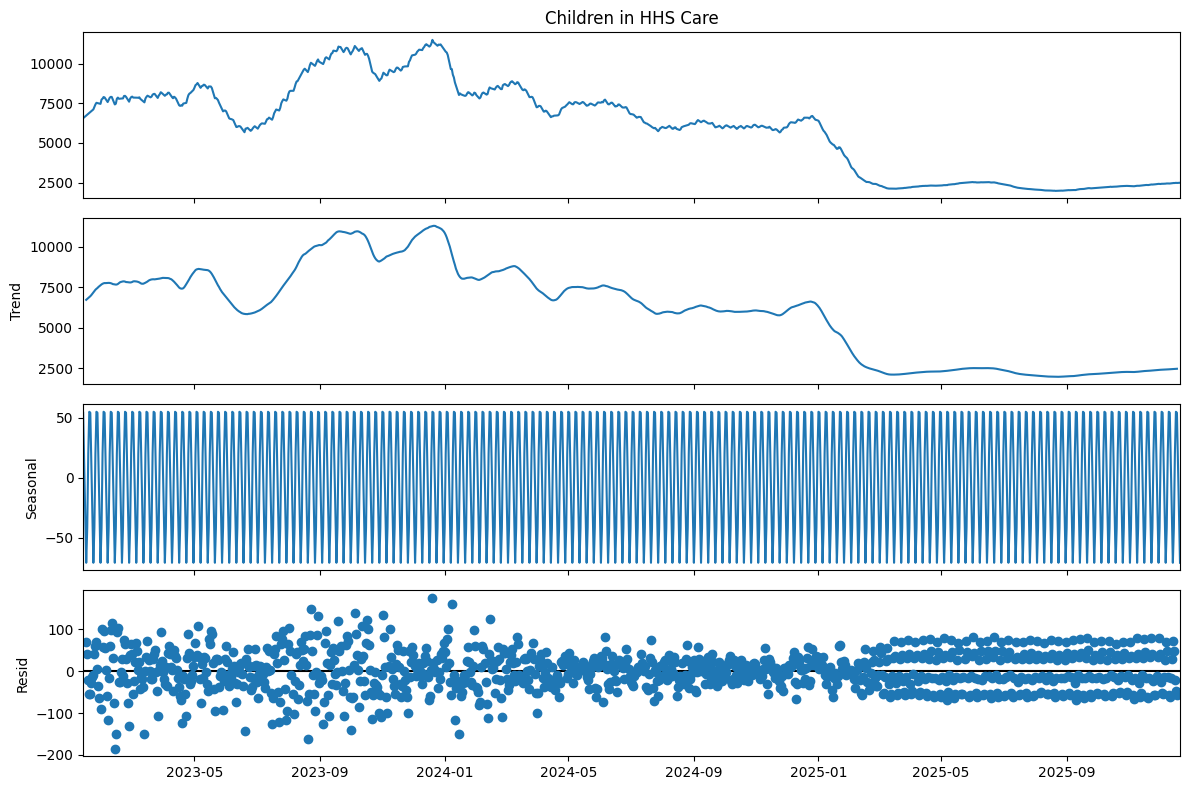

In [ ]:
# Prepare a daily series for decomposition

daily_series = ts_data['Children in HHS Care'].asfreq('D')

# Estimate missing dates for decomposition only
daily_series = daily_series.interpolate(method='time')

print("Daily observations after interpolation:", len(daily_series))
print("Missing values remaining:", daily_series.isna().sum())

# Decompose into trend, seasonality, and residuals
decomposition = seasonal_decompose(
    daily_series,
    model='additive',
    period=7
)

# Plot the components
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

In [ ]:
# Feature engineering

features = data.sort_values('Date').copy()
target = 'Children in HHS Care'

# Lag features
features['HHS_Lag_1'] = features[target].shift(1)
features['HHS_Lag_7'] = features[target].shift(7)
features['HHS_Lag_14'] = features[target].shift(14)

# Rolling means and variances
features['Rolling_Mean_7'] = features[target].shift(1).rolling(7).mean()
features['Rolling_Mean_14'] = features[target].shift(1).rolling(14).mean()

features['Rolling_Var_7'] = features[target].shift(1).rolling(7).var()
features['Rolling_Var_14'] = features[target].shift(1).rolling(14).var()

# Flow-based signal: transfers minus discharges
features['Transfer_Discharge_Flow'] = (
    features['Children transferred out of CBP custody']
    - features['Children discharged from HHS Care']
)

# Calendar features
features['Day_of_Week'] = features['Date'].dt.dayofweek
features['Month'] = features['Date'].dt.month

print("Feature dataset shape:", features.shape)
print("\nNew feature columns:")
print(features.columns.tolist())

display(features.head(18))

Feature dataset shape: (720, 18)

New feature columns:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care', 'Weekday', 'Year_Month', 'HHS_Lag_1', 'HHS_Lag_7', 'HHS_Lag_14', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Var_7', 'Rolling_Var_14', 'Transfer_Discharge_Flow', 'Day_of_Week', 'Month']


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Weekday,Year_Month,HHS_Lag_1,HHS_Lag_7,HHS_Lag_14,Rolling_Mean_7,Rolling_Mean_14,Rolling_Var_7,Rolling_Var_14,Transfer_Discharge_Flow,Day_of_Week,Month
0,2023-01-12,33,53,34,6566,436,Thursday,2023-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-402,3,1
1,2023-01-22,32,49,39,7122,227,Sunday,2023-01,6566.0,NaN,NaN,NaN,NaN,NaN,NaN,-188,6,1
2,2023-01-23,32,50,39,7280,181,Monday,2023-01,7122.0,NaN,NaN,NaN,NaN,NaN,NaN,-142,0,1
3,2023-01-24,47,42,47,7433,175,Tuesday,2023-01,7280.0,NaN,NaN,NaN,NaN,NaN,NaN,-128,1,1
4,2023-01-25,20,22,41,7538,180,Wednesday,2023-01,7433.0,NaN,NaN,NaN,NaN,NaN,NaN,-139,2,1
5,2023-01-29,23,45,11,7472,303,Sunday,2023-01,7538.0,NaN,NaN,NaN,NaN,NaN,NaN,-292,6,1
6,2023-01-30,34,54,29,7743,196,Monday,2023-01,7472.0,NaN,NaN,NaN,NaN,NaN,NaN,-167,0,1
7,2023-01-31,26,36,36,7803,158,Tuesday,2023-01,7743.0,6566.0,NaN,7307.714286,NaN,145098.238095,NaN,-122,1,1
8,2023-02-01,25,32,27,7903,231,Wednesday,2023-02,7803.0,7122.0,NaN,7484.428571,NaN,57860.285714,NaN,-204,2,2
9,2023-02-02,15,13,23,7879,298,Thursday,2023-02,7903.0,7280.0,NaN,7596.000000,NaN,50645.333333,NaN,-275,3,2


In [ ]:
# Exponential Smoothing model

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Use the daily series prepared in Step 7
model_series = daily_series.dropna()

split_index = int(len(model_series) * 0.8)
es_train = model_series.iloc[:split_index]
es_test = model_series.iloc[split_index:]

# Fit Holt-Winters additive trend and weekly seasonality
es_model = ExponentialSmoothing(
    es_train,
    trend='add',
    seasonal='add',
    seasonal_periods=7,
    initialization_method='estimated'
)

es_fit = es_model.fit()
es_predictions = es_fit.forecast(len(es_test))

# Evaluate
es_mae = mean_absolute_error(es_test, es_predictions)
es_rmse = np.sqrt(mean_squared_error(es_test, es_predictions))

nonzero = es_test.to_numpy() != 0
es_mape = np.mean(
    np.abs(
        (es_test.to_numpy()[nonzero] -
         np.asarray(es_predictions)[nonzero]) /
        es_test.to_numpy()[nonzero]
    )
) * 100

print("Exponential Smoothing Results")
print("MAE:", round(es_mae, 2))
print("RMSE:", round(es_rmse, 2))
print("MAPE (%):", round(es_mape, 2))

Exponential Smoothing Results
MAE: 2146.19
RMSE: 2422.76
MAPE (%): 96.44


In [ ]:
# SARIMA model

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Use the daily series from Step 7
model_series = daily_series.dropna()

split_index = int(len(model_series) * 0.8)
sarima_train = model_series.iloc[:split_index]
sarima_test = model_series.iloc[split_index:]

# Fit SARIMA with weekly seasonality
sarima_model = SARIMAX(
    sarima_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)
sarima_predictions = sarima_fit.forecast(steps=len(sarima_test))

# Evaluate
sarima_mae = mean_absolute_error(sarima_test, sarima_predictions)
sarima_rmse = np.sqrt(
    mean_squared_error(sarima_test, sarima_predictions)
)

actual = sarima_test.to_numpy()
predicted = np.asarray(sarima_predictions)
nonzero = actual != 0

sarima_mape = np.mean(
    np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])
) * 100

print("SARIMA(1,1,1) x (1,1,1,7) Results")
print("MAE:", round(sarima_mae, 2))
print("RMSE:", round(sarima_rmse, 2))
print("MAPE (%):", round(sarima_mape, 2))

SARIMA(1,1,1) x (1,1,1,7) Results
MAE: 356.48
RMSE: 510.13
MAPE (%): 15.4


In [ ]:
# Random Forest forecasting model

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

target = 'Children in HHS Care'

feature_cols = [
    'HHS_Lag_1',
    'HHS_Lag_7',
    'HHS_Lag_14',
    'Rolling_Mean_7',
    'Rolling_Mean_14',
    'Rolling_Var_7',
    'Rolling_Var_14',
    'Transfer_Discharge_Flow',
    'Day_of_Week',
    'Month'
]

rf_data = features.dropna(subset=feature_cols + [target]).copy()

split_index = int(len(rf_data) * 0.8)
rf_train = rf_data.iloc[:split_index]
rf_test = rf_data.iloc[split_index:]

X_train = rf_train[feature_cols]
y_train = rf_train[target]
X_test = rf_test[feature_cols]
y_test = rf_test[target]

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

actual = y_test.to_numpy()
nonzero = actual != 0
rf_mape = np.mean(
    np.abs((actual[nonzero] - rf_predictions[nonzero]) /
           actual[nonzero])
) * 100

print("Random Forest Results")
print("Training records:", len(rf_train))
print("Testing records:", len(rf_test))
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("MAPE (%):", round(rf_mape, 2))

Random Forest Results
Training records: 564
Testing records: 142
MAE: 64.3
RMSE: 86.27
MAPE (%): 2.97


In [ ]:
# Gradient Boosting forecasting model

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)
gb_predictions = gb_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))

actual = y_test.to_numpy()
nonzero = actual != 0

gb_mape = np.mean(
    np.abs((actual[nonzero] - gb_predictions[nonzero]) /
           actual[nonzero])
) * 100

print("Gradient Boosting Results")
print("MAE:", round(gb_mae, 2))
print("RMSE:", round(gb_rmse, 2))
print("MAPE (%):", round(gb_mape, 2))

Gradient Boosting Results
MAE: 60.55
RMSE: 80.46
MAPE (%): 2.78


Random Forest Feature Importance:


,Feature,Importance
0,HHS_Lag_1,0.8366
3,Rolling_Mean_7,0.1028
1,HHS_Lag_7,0.0283
4,Rolling_Mean_14,0.0231
2,HHS_Lag_14,0.0062
9,Month,0.0009
7,Transfer_Discharge_Flow,0.0007
8,Day_of_Week,0.0005
5,Rolling_Var_7,0.0004
6,Rolling_Var_14,0.0004


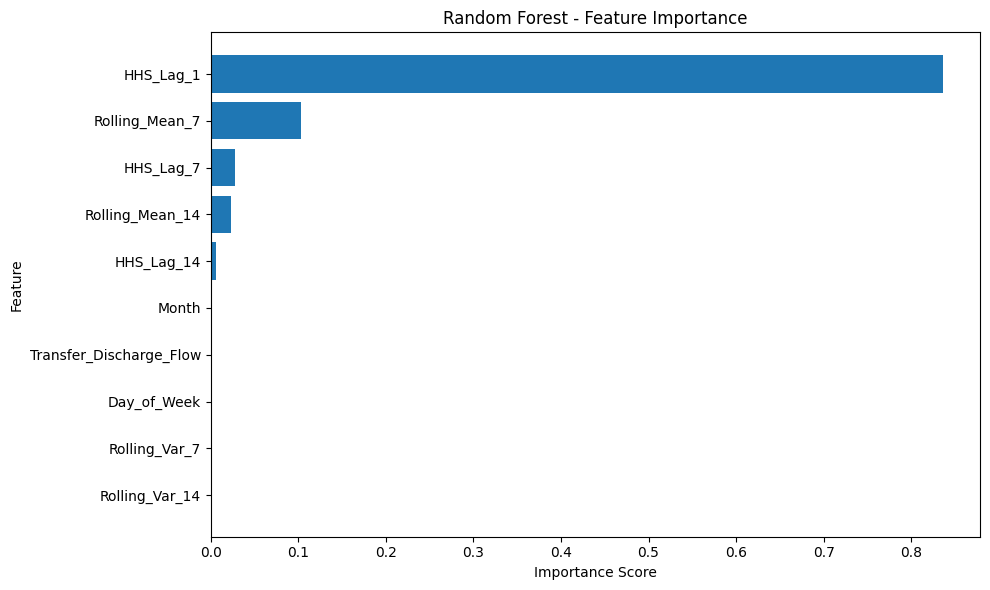

In [ ]:
# Random Forest feature importance

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("Random Forest Feature Importance:")
display(importance.round(4))

plt.figure(figsize=(10, 6))
plt.barh(importance['Feature'], importance['Importance'])
plt.gca().invert_yaxis()
plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
# Prepare a consistent chronological dataset

import pandas as pd
import numpy as np

target = 'Children in HHS Care'

observed_data = data[['Date', target]].copy()
observed_data['Date'] = pd.to_datetime(observed_data['Date'])
observed_data[target] = pd.to_numeric(
    observed_data[target], errors='coerce'
)

observed_data = (
    observed_data.dropna(subset=['Date', target])
    .sort_values('Date')
    .drop_duplicates('Date')
    .reset_index(drop=True)
)

split_index = int(len(observed_data) * 0.8)

observed_train = observed_data.iloc[:split_index].copy()
observed_test = observed_data.iloc[split_index:].copy()

print("Total observed records:", len(observed_data))
print("Training records:", len(observed_train))
print("Testing records:", len(observed_test))
print("Training period:",
      observed_train['Date'].min(), "to",
      observed_train['Date'].max())
print("Testing period:",
      observed_test['Date'].min(), "to",
      observed_test['Date'].max())

Total observed records: 720
Training records: 576
Testing records: 144
Training period: 2023-01-12 00:00:00 to 2025-05-13 00:00:00
Testing period: 2025-05-14 00:00:00 to 2025-12-21 00:00:00


In [ ]:
# Baseline forecasts on the original observed test set

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

history = observed_train[target].astype(float).tolist()
actual_values = observed_test[target].astype(float).to_numpy()

naive_predictions = []
ma7_predictions = []

for actual in actual_values:
    # Naive: latest previously observed value
    naive_predictions.append(history[-1])

    # Moving average: mean of the last 7 recorded observations
    ma7_predictions.append(np.mean(history[-7:]))

    # Update history after forecasting the current observation
    history.append(actual)

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae_value = mean_absolute_error(actual, predicted)
    rmse_value = np.sqrt(mean_squared_error(actual, predicted))

    nonzero = actual != 0
    mape_value = (
        np.mean(np.abs(
            (actual[nonzero] - predicted[nonzero]) /
            actual[nonzero]
        )) * 100
        if nonzero.any() else np.nan
    )

    return mae_value, rmse_value, mape_value

naive_metrics = calculate_metrics(actual_values, naive_predictions)
ma7_metrics = calculate_metrics(actual_values, ma7_predictions)

baseline_comparison = pd.DataFrame({
    'Model': ['Naive Forecast', '7-Observation Moving Average'],
    'MAE': [naive_metrics[0], ma7_metrics[0]],
    'RMSE': [naive_metrics[1], ma7_metrics[1]],
    'MAPE (%)': [naive_metrics[2], ma7_metrics[2]]
})

display(baseline_comparison.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Forecast,10.39,14.17,0.46
1,7-Observation Moving Average,33.25,40.61,1.48


In [ ]:
# Leakage-aware machine-learning evaluation

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

target = 'Children in HHS Care'

ml_data = observed_data.copy()

# Features from previously recorded observations
ml_data['Lag_1'] = ml_data[target].shift(1)
ml_data['Lag_7'] = ml_data[target].shift(7)
ml_data['Lag_14'] = ml_data[target].shift(14)

ml_data['Mean_7'] = ml_data[target].shift(1).rolling(7).mean()
ml_data['Mean_14'] = ml_data[target].shift(1).rolling(14).mean()
ml_data['Var_7'] = ml_data[target].shift(1).rolling(7).var()
ml_data['Var_14'] = ml_data[target].shift(1).rolling(14).var()

# Calendar features for the date being predicted
ml_data['Day_of_Week'] = ml_data['Date'].dt.dayofweek
ml_data['Month'] = ml_data['Date'].dt.month

feature_cols = [
    'Lag_1', 'Lag_7', 'Lag_14',
    'Mean_7', 'Mean_14', 'Var_7', 'Var_14',
    'Day_of_Week', 'Month'
]

ml_data = ml_data.dropna(subset=feature_cols + [target]).reset_index(drop=True)

# Use the same chronological cutoff date as the original split
cutoff_date = observed_test['Date'].min()

ml_train = ml_data[ml_data['Date'] < cutoff_date]
ml_test = ml_data[ml_data['Date'] >= cutoff_date]

X_train = ml_train[feature_cols]
y_train = ml_train[target]
X_test = ml_test[feature_cols]
y_test = ml_test[target]

rf_final = RandomForestRegressor(
    n_estimators=200, max_depth=10, random_state=42
)
gb_final = GradientBoostingRegressor(
    n_estimators=200, learning_rate=0.05,
    max_depth=3, random_state=42
)

rf_final.fit(X_train, y_train)
gb_final.fit(X_train, y_train)

rf_final_predictions = rf_final.predict(X_test)
gb_final_predictions = gb_final.predict(X_test)

def metrics_for(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae_value = mean_absolute_error(actual, predicted)
    rmse_value = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = actual != 0
    mape_value = (
        np.mean(np.abs(
            (actual[nonzero] - predicted[nonzero]) /
            actual[nonzero]
        )) * 100 if nonzero.any() else np.nan
    )
    return mae_value, rmse_value, mape_value

rf_final_metrics = metrics_for(y_test, rf_final_predictions)
gb_final_metrics = metrics_for(y_test, gb_final_predictions)

ml_comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Gradient Boosting'],
    'MAE': [rf_final_metrics[0], gb_final_metrics[0]],
    'RMSE': [rf_final_metrics[1], gb_final_metrics[1]],
    'MAPE (%)': [rf_final_metrics[2], gb_final_metrics[2]]
})

print("Training records:", len(ml_train))
print("Testing records:", len(ml_test))
display(ml_comparison.round(2))

Training records: 562
Testing records: 144


,Model,MAE,RMSE,MAPE (%)
0,Random Forest,67.78,89.53,3.12
1,Gradient Boosting,70.42,90.46,3.26


In [ ]:
# Combine baseline and machine-learning results

final_comparison = pd.concat(
    [baseline_comparison, ml_comparison],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    'MAE'
).reset_index(drop=True)

final_comparison.insert(
    0, 'Rank', range(1, len(final_comparison) + 1)
)

print("FINAL COMPARISON — ONE-STEP-AHEAD FORECASTS")
display(final_comparison.round(2))

print("\nBest model based on MAE:")
print(final_comparison.iloc[0]['Model'])

FINAL COMPARISON — ONE-STEP-AHEAD FORECASTS


,Rank,Model,MAE,RMSE,MAPE (%)
0,1,Naive Forecast,10.39,14.17,0.46
1,2,7-Observation Moving Average,33.25,40.61,1.48
2,3,Random Forest,67.78,89.53,3.12
3,4,Gradient Boosting,70.42,90.46,3.26



Best model based on MAE:
Naive Forecast


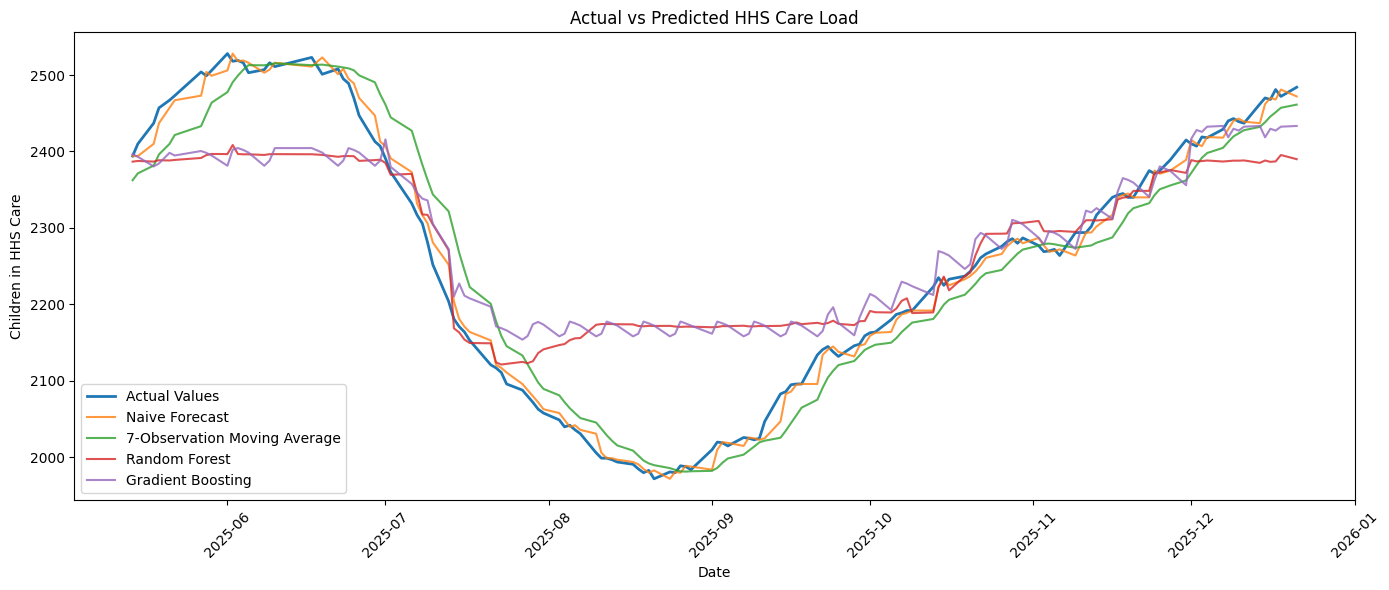

In [ ]:
# Actual vs predicted values

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    observed_test['Date'],
    observed_test[target],
    label='Actual Values',
    linewidth=2
)

plt.plot(
    observed_test['Date'],
    naive_predictions,
    label='Naive Forecast',
    alpha=0.8
)

plt.plot(
    observed_test['Date'],
    ma7_predictions,
    label='7-Observation Moving Average',
    alpha=0.8
)

plt.plot(
    ml_test['Date'],
    rf_final_predictions,
    label='Random Forest',
    alpha=0.8
)

plt.plot(
    ml_test['Date'],
    gb_final_predictions,
    label='Gradient Boosting',
    alpha=0.8
)

plt.title('Actual vs Predicted HHS Care Load')
plt.xlabel('Date')
plt.ylabel('Children in HHS Care')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Export model comparison results

final_comparison.to_csv(
    'final_model_comparison.csv',
    index=False
)

print("Comparison table saved successfully!")

# Download the CSV file to your device
from google.colab import files
files.download('final_model_comparison.csv')

Comparison table saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

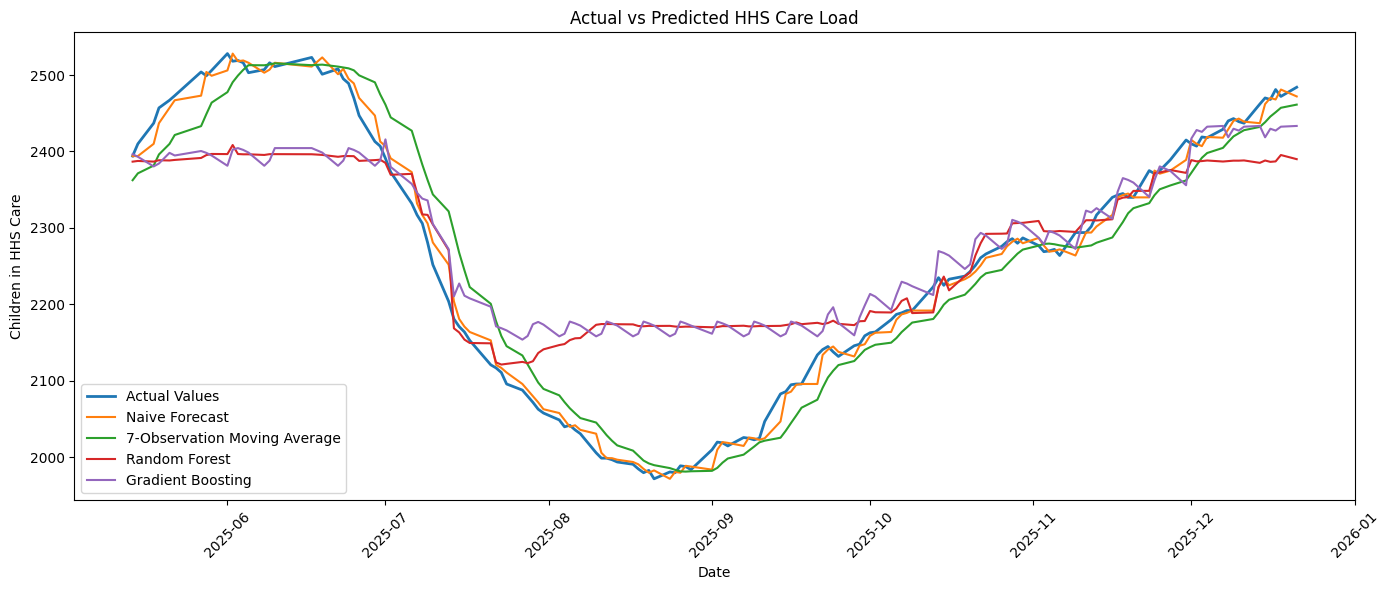

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Save the forecast comparison chart

plt.figure(figsize=(14, 6))

plt.plot(
    observed_test['Date'],
    observed_test[target],
    label='Actual Values',
    linewidth=2
)

plt.plot(
    observed_test['Date'],
    naive_predictions,
    label='Naive Forecast'
)

plt.plot(
    observed_test['Date'],
    ma7_predictions,
    label='7-Observation Moving Average'
)

plt.plot(
    ml_test['Date'],
    rf_final_predictions,
    label='Random Forest'
)

plt.plot(
    ml_test['Date'],
    gb_final_predictions,
    label='Gradient Boosting'
)

plt.title('Actual vs Predicted HHS Care Load')
plt.xlabel('Date')
plt.ylabel('Children in HHS Care')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    'actual_vs_predicted.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

from google.colab import files
files.download('actual_vs_predicted.png')